In [14]:
# Step 1: Libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Model

In [20]:
# Load Data 
faces = fetch_olivetti_faces(shuffle=False)
X = faces.images      
y = faces.target      
print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of people:", len(np.unique(y)))

Images: (400, 64, 64)
Labels: (400,)
Number of people: 40


In [16]:
# Step 7: Model 1's Architecture
input_tensor = Input(shape=(64, 64, 1))

# Convolution Neural Network Model
conv = Conv2D(filters=16, kernel_size=(3, 3), strides=1,
              padding="same", activation="relu", name="conv_layer")(input_tensor)
pool = MaxPooling2D(pool_size=(2, 2), strides=2,
                    padding="valid", name="pool_layer")(conv)
flat = Flatten(name="flatten")(pool)
output = Dense(40, activation="softmax", name="output_layer")(flat)

model1 = Model(inputs=input_tensor, outputs=output)

# Compiling model1
model1.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])
model1.summary()

# Train (prints the output from training)
history1 = model1.fit(X_train, y_train_cat,
                      epochs=20, batch_size=10, verbose=1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv_layer (Conv2D)                  │ (None, 64, 64, 16)          │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool_layer (MaxPooling2D)            │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 40)                  │         655,400 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 655,560 (2.50 MB)

 Trainable params: 655,560 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.0200 - loss: 4.7203
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.0250 - loss: 3.7343
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.2350 - loss: 3.4289
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4000 - loss: 3.0378
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5700 - loss: 2.6428
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.7050 - loss: 2.0599
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8550 - loss: 1.2806
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9100 - loss: 0.8177
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9550 - loss: 0.5016
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9900 - loss: 0.2983
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9900 - loss: 0.1548
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy:

In [17]:
# Step 8: Model 1's loss and accuracy
loss, accuracy = model1.evaluate(X_test, y_test_cat, verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy:.4f}")

Test loss: 0.3249
Test accuracy: 0.9100


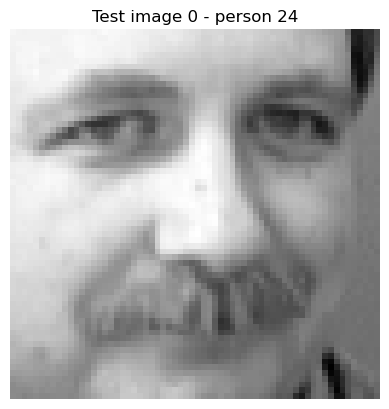

In [18]:
# Step 9: Print image
idx = 0  # pick any index from 0 to 199
plt.imshow(X_test[idx].reshape(64, 64), cmap="gray")
plt.title(f"Test image {idx} - person {y_test[idx]}")
plt.axis("off")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Conv feature maps: (1, 64, 64, 16)
Pool feature maps: (1, 32, 32, 16)


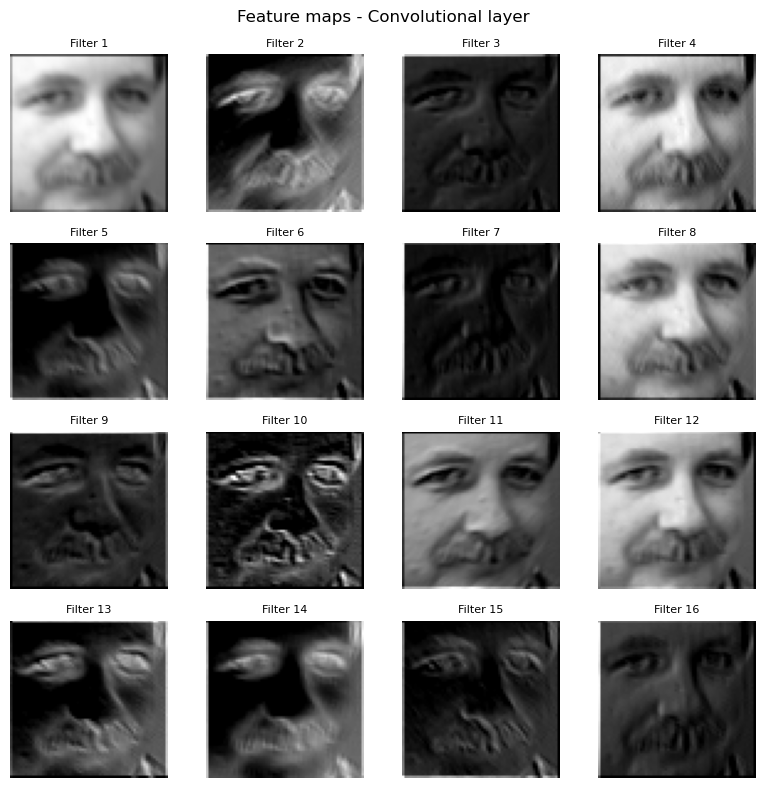

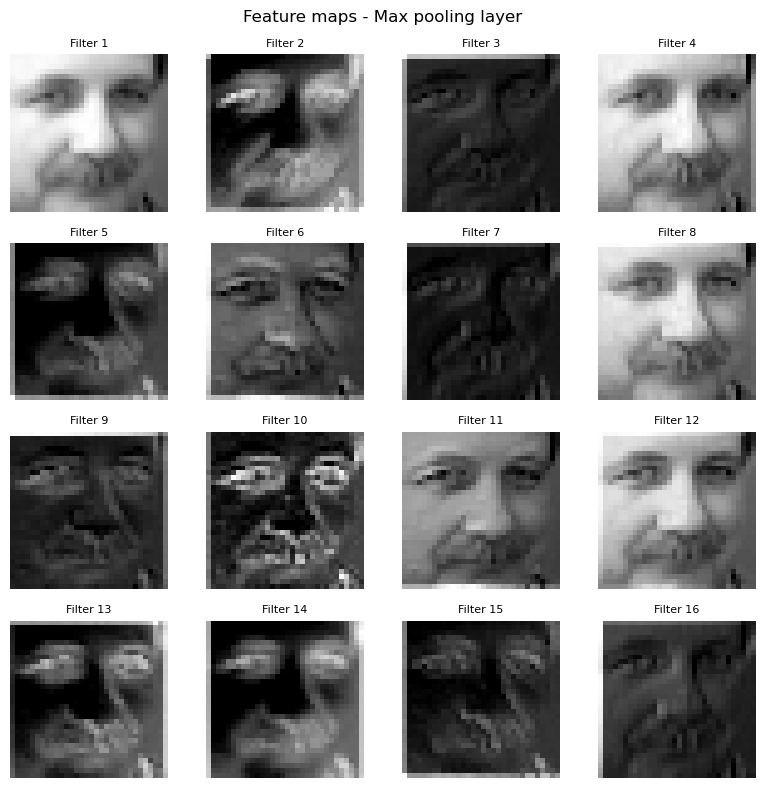

In [19]:
# Step 10: Feature maps
feature_model = Model(inputs=model1.input, outputs=[conv, pool])
img = X_test[idx:idx + 1]                       # shape (1, 64, 64, 1)
conv_maps, pool_maps = feature_model.predict(img)
print("Conv feature maps:", conv_maps.shape)    # (1, 64, 64, 16)
print("Pool feature maps:", pool_maps.shape)    # (1, 32, 32, 16)

# For loop: plot all 16 maps for each layer
for name, maps in [("Convolutional layer", conv_maps),
                   ("Max pooling layer", pool_maps)]:
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(maps[0, :, :, i], cmap="gray")
        ax.set_title(f"Filter {i + 1}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Feature maps - {name}")
    plt.tight_layout()
    plt.show()